In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
def hamiltonian_matrix(delta_x,potential_values):
  interior_points = len(potential_values)

  main_diag = 1/(delta_x**2) + potential_values
  off_diag  = np.full(interior_points-1,-1/(2*(delta_x**2)))

  hamiltonian = (np.diag(main_diag) + np.diag(off_diag,k=1) + np.diag(off_diag,k=-1))

  return hamiltonian

In [2]:
def finite_potential_well(xi,xf,V0,interior_grid):
  potential_values = np.zeros_like(interior_grid, dtype=float)
  mask = (interior_grid >= xi) & (interior_grid <= xf)
  potential_values[mask] = V0
  return potential_values

In [3]:
def solve_and_plot(x_min,x_max,xi,xf,V0,interior_points,state_idx):
  delta_x = (x_max - x_min)/(interior_points + 1)
  interior_grid = (x_min + delta_x*np.arange(1,interior_points + 1))

  potential_values = finite_potential_well(xi,xf,V0,interior_grid)
  hamiltonian = hamiltonian_matrix(delta_x,potential_values)

  eigenvalues,eigenvectors = np.linalg.eigh(hamiltonian)

  phi_interior = eigenvectors[:,state_idx]
  energy_value = eigenvalues[state_idx]
  phi = np.concatenate(([0.0],phi_interior,[0.0]))
  normalization = np.sum(np.abs(phi)**2)*delta_x
  phi_normalized = phi/np.sqrt(normalization)
  full_grid = np.concatenate(([x_min],interior_grid,[x_max]))
  quantum_number = state_idx + 1

  plt.plot(full_grid,phi_normalized,label=f"State {quantum_number}")
  plt.axhline(0,linewidth=0.8,linestyle="--")
  plt.xlabel("Dimensionless position, x")
  plt.ylabel(r"Eigenvector $\phi(x)$")
  plt.title(f"Eigenvalue n = {quantum_number}, "f"Energy = {energy_value:.6f}")
  plt.grid(alpha=0.5)
  plt.legend()
  plt.show()

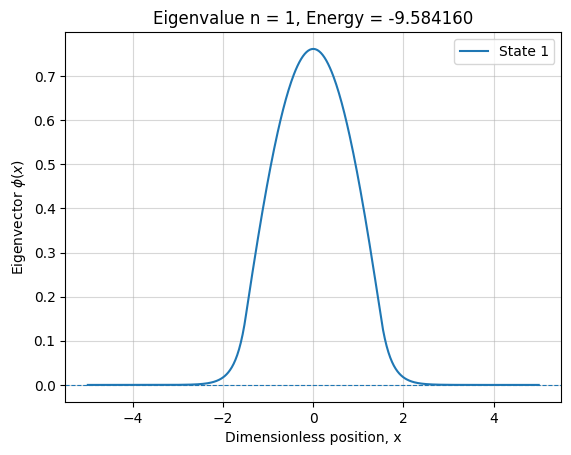

In [5]:
x_min=-5.0
x_max=5.0
xi=-1.5
xf=1.5
V0=-10.0
interior_points=500
state_idx=0

solve_and_plot(x_min,x_max,xi,xf,V0,interior_points,state_idx)